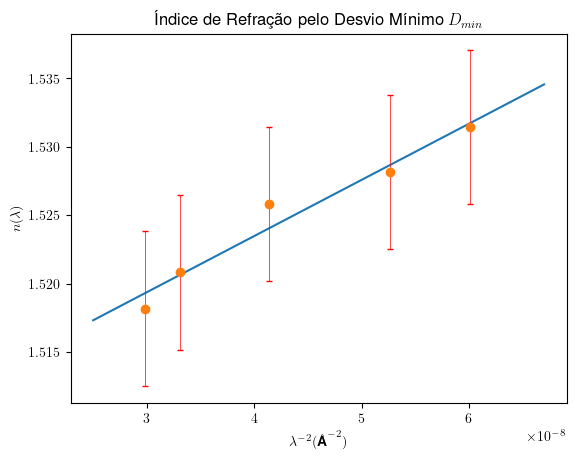

a = 410517.8740436268 incerteza: 49153.61212265017 em Angstom quadrado.
b = 1.5070546473738569 incerteza: 0.0022072557785872593 adimensional.


In [24]:
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "sans-serif",
    "font.sans-serif": "Helvetica",
})
from scipy.optimize import curve_fit

# dados:
# converti todos os ângulos para ângulos decimais para simplificar o cálculo. Como as funções do numpy calculam 
# sin e cos em radianos, nossos ângulos devem ser convertidos para radians.

theta0 = np.radians(114.45) 
theta = np.array([75.68333, 75.45, 75.00833, 74.8, 74.50833], dtype = float)
thetaR = np.radians(theta) 
Dmin = -1*(thetaR - theta0)
err = np.radians(0.5)
A = np.radians(60)
def indice(a, b):
    n = (np.sin(0.5*( b + a)))/(np.sin(a/2))
    return n
    
# o erro de n é determinado pela propagação de erro. Não é uma derivada difícil, só bem grande.
n_err = (err*np.cos(0.5*(Dmin + A)))/(2*np.sin(A/2))

# os lambdas (L's) estão em Anströms, 10⁻¹⁰ m, conforme o roteiro.
l = np.array([5791 ,5500 ,4916, 4358, 4078],dtype = float)
L = l**(-2)

# defino uma função e aplico um ajuste linear
def ajuste(x, c, d):
    return c*x + d

popt, pcov = curve_fit(ajuste, L, indice(A, Dmin))
c, d = popt
sigma_c, sigma_d = np.sqrt(np.diag(pcov))

# gráfico

S = np.linspace(2.5*(10**(-8)), 6.7*(10**(-8)))
plt.plot(S, ajuste(S, c, d ), label='Ajuste')
plt.errorbar(L, indice(A, Dmin), yerr= n_err , fmt='o', 
             ecolor='red', capsize=2, elinewidth=0.5)

plt.xlabel(r'$\lambda^{-2} (\textbf{\AA}^{-2})$')
plt.ylabel(r'$n(\lambda)$')
plt.title(r"Índice de Refração pelo Desvio Mínimo $D_{min}$")
plt.savefig(r"exp2a.png")
plt.show()

print("a =", c, "incerteza:", sigma_c, "em Angstom quadrado.")
print("b =", d, "incerteza:", sigma_d, "adimensional.")

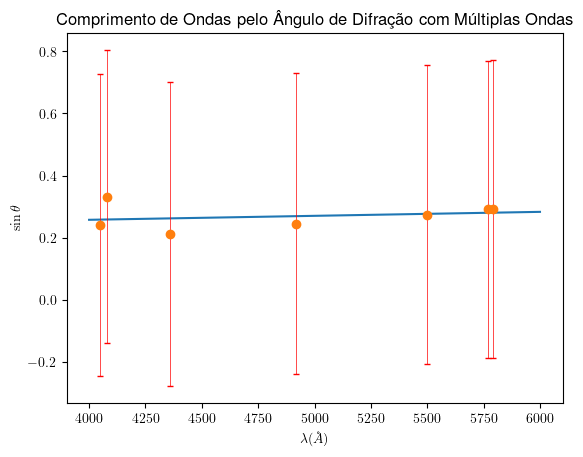

a = 1.2787491425969577e-05 incerteza: 2.2465375647547542e-05 em Angstom.
b = 0.2064735348836516 incerteza: 0.11176257139856025 adimensional.


In [25]:
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "sans-serif",
    "font.sans-serif": "Helvetica",
})
from scipy.optimize import curve_fit

# dados:
# converti todos os ângulos para ângulos decimais para simplificar o cálculo. Como as funções do numpy calculam 
# sin e cos em radianos, nossos ângulos devem ser convertidos para radians.

#angulos medidos
theta0 = np.radians(262.61666667) 
theta1 = np.array([245.50833333, 245.66666667, 246.62777778, 248.13333333, 248.20833333, 249.90833333, 236.28333333], dtype = float)
theta2 = np.array([279.48333333, 279.53333333, 278.38333333, 276.04166667, 276.60833333, 274.25833333, 275.01666667], dtype = float)

#diferença entre os ângulos, o ângulo efetivo:
Dtheta1 = theta0 - theta1
Dtheta2 = theta2 - theta0

#a média dos ângulos encontrados p m=1 e m=-1

E = []
for i in range(len(Dtheta1)):
    D = (Dtheta1[i] +Dtheta2[i])*0.5
    E.append(D)

#finalmente... o valor em radianos:
E_radiand = np.radians(E)
err = np.cos(E_radiand)*0.5

# o seno que queremos
thetaSin = np.sin(E_radiand)


# os lambdas (L's) estão em Anströms, 10⁻¹⁰ m, conforme o roteiro.
l = np.array([5791 ,5770 , 5500,4047, 4916, 4358, 4078],dtype = float)

# defino uma função e aplico um ajuste linear
def ajuste(x, a, b):
    return a*x + b

popt, pcov = curve_fit(ajuste, l, thetaSin)
a, b = popt
sigma_a, sigma_b = np.sqrt(np.diag(pcov))

# gráfico

S = np.linspace(4000, 6000)
plt.plot(S, ajuste(S, a, b), label='Ajuste')
plt.errorbar(l, thetaSin, yerr= err, fmt='o', 
             ecolor='red', capsize=2, elinewidth=0.5)

plt.xlabel(r'$\lambda (\r{A})$')
plt.ylabel(r'$\sin{\theta}$')
plt.title(r"Comprimento de Ondas pelo Ângulo de Difração com Múltiplas Ondas")
plt.savefig(r"exp2b.png")

plt.show()

print("a =", a, "incerteza:", sigma_a, "em Angstom.")
print("b =", b, "incerteza:", sigma_b, "adimensional.")